<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# The windiest three days of the past year 🌬️
### Copernicus Climate Change Service · ERA5 reanalysis · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/sweden/storm_era5.ipynb)

Over southern and central Sweden and the seas around it, the windiest three days of the past year were
**4 to 6 April 2026**. The strongest winds came on the afternoon of **Sunday 5 April**, when a westerly gale blew through the
Skagerrak onto the Swedish west coast. This notebook maps 16 UTC that day (18:00 in Sweden) from **ERA5**, ECMWF's
reconstruction of the weather everywhere on Earth, every hour since 1940, made for the European Union.

**What you need:** a Google account (to use Colab) and a free Copernicus account (next step). No fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ERA5 hourly](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels), about 31 km | 10 m wind and gust, 24 hours of 5 April 2026 | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to Sweden (SMHI, Norrköping), 2026. ERA5 sees the atmosphere at about 31 km: it shows the size and track of the storm, not the detail along the coast.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels?tab=download) on the Climate Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the day, the hour and the area

In [4]:
DAY  = "2026-04-05"
HOUR = "2026-04-05T16:00"                    # the hour to map (UTC)
AREA = [62.0, 4.0, 54.0, 22.0]               # north, west, south, east: Skagerrak and Kattegat to Gotland
PLACES = [("Stockholm", 59.329, 18.069), ("Norrköping", 58.588, 16.192), ("Gothenburg", 57.709, 11.975),
          ("Malmö", 55.605, 13.004), ("Visby", 57.634, 18.295)]

def label_places(chart, places):
    for name, la, lo in places:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get ERA5 hourly 10 m wind and gust from the Climate Data Store

In [5]:
era5 = ekd.from_source("cds", "reanalysis-era5-single-levels", {
    "product_type": "reanalysis",
    "variable": ["10m_u_component_of_wind", "10m_v_component_of_wind", "10m_wind_gust_since_previous_post_processing"],
    "year": DAY[:4], "month": DAY[5:7], "day": DAY[8:], "time": [f"{h:02d}:00" for h in range(24)],
    "area": AREA, "data_format": "grib"})
ds = era5.to_xarray(time_dims=["valid_time"])
speed = np.hypot(ds["10u"], ds["10v"])                                 # wind speed, m/s
gust = ds[[v for v in ds.data_vars if v not in ("10u", "10v")][0]]   # highest gust in the hour before
print(f"Strongest 10 m wind on {DAY}: {float(speed.max()):.1f} m/s ({float(speed.max()) * 3.6:.0f} km/h)")
for n, la, lo in PLACES:
    g = gust.sel(latitude=la, longitude=lo, method="nearest")
    print(f"  {n:10s} strongest gust {float(g.max()):4.1f} m/s ({float(g.max()) * 3.6:3.0f} km/h)")

Strongest 10 m wind on 2026-04-05: 25.4 m/s (92 km/h)
  Stockholm  strongest gust 19.8 m/s ( 71 km/h)
  Norrköping strongest gust 23.8 m/s ( 86 km/h)
  Gothenburg strongest gust 35.7 m/s (128 km/h)
  Malmö      strongest gust 21.2 m/s ( 76 km/h)
  Visby      strongest gust 23.7 m/s ( 85 km/h)


## 3 · Map the wind at one hour

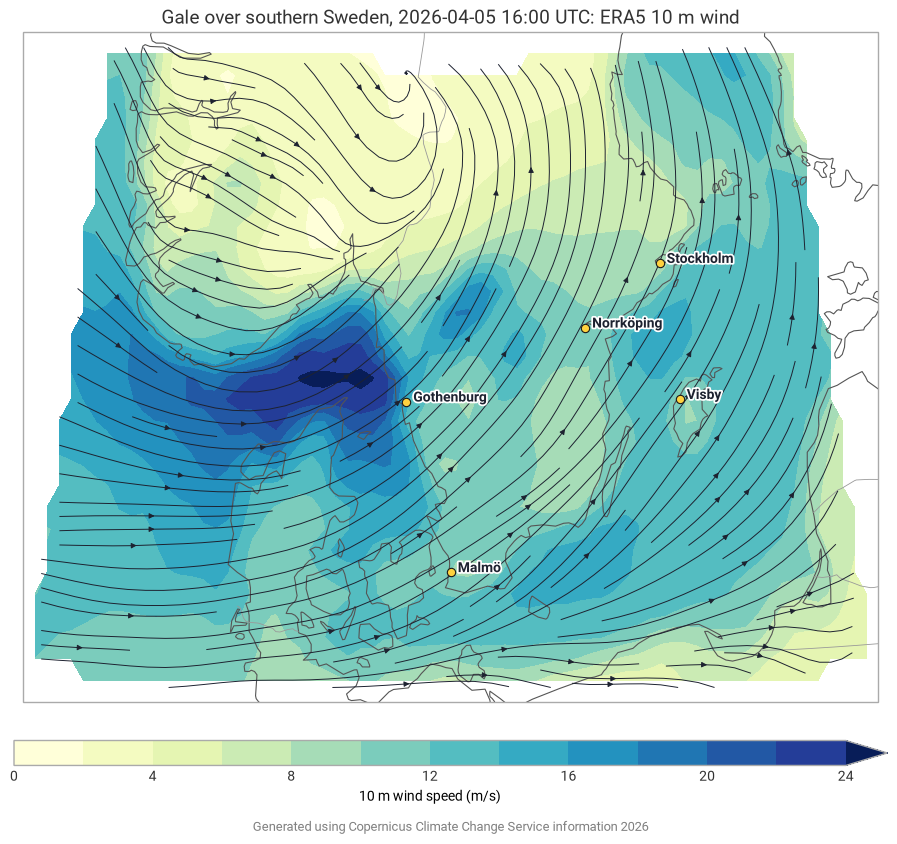

In [6]:
u, v, s = ds["10u"].sel(valid_time=HOUR), ds["10v"].sel(valid_time=HOUR), speed.sel(valid_time=HOUR)
style = ekp.styles.Style(levels=list(range(0, 25, 2)), colors="YlGnBu", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(s, style=style)
chart.ax.streamplot(u.longitude.values, u.latitude.values, u.values, v.values, color="#1d2230", density=1.6,
                    linewidth=0.7, arrowsize=0.8, transform=ccrs.PlateCarree(), zorder=5)
chart.coastlines(linewidth=0.8); chart.borders(linewidth=0.6)
label_places(chart, PLACES)
chart.legend(label="10 m wind speed (m/s)")
chart.title(f"Gale over southern Sweden, {HOUR.replace('T', ' ')} UTC: ERA5 10 m wind", fontsize=14)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("storm_era5.png")
chart.show()

## 4 · Your turn 🌍

- **Another hour:** change `HOUR`, for example `"2026-04-05T10:00"`, as the gale came in from the North Sea.
- **The runner-up:** `DAY, HOUR = "2026-10-25", "2026-10-25T12:00"`, the windiest single day of the past year.
- **Gusts instead of mean wind:** map `gust.sel(valid_time=HOUR)` instead of `s`, with levels up to 40.
- **A famous storm:** `DAY = "2005-01-08"` (Gudrun) with `HOUR = "2005-01-08T18:00"`; ERA5 goes back to 1940.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Climate Change Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)